# Fourier ptychography: a synthetic aperture from an LED array

A low NA objective sees a large field but resolves little; a high NA
objective resolves fine detail in a small field. The number of resolved
pixels, the **space-bandwidth product**, is limited to some ten megapixels
for any single objective. Fourier ptychographic microscopy (FPM, Zheng,
Horstmeyer and Yang 2013) breaks this limit with a cheap trick: replace
the condenser by a matrix of LEDs, take one low resolution image per LED,
and stitch the images together in Fourier space.

Each LED illuminates the sample with a plane wave of a different
direction, which shifts the object spectrum (notebook
[52](52_abbe_image_formation.ipynb), oblique illumination), so each image
shows a different disk of the spectrum. LEDs beyond the objective's NA
give **dark field** images with the high frequencies. The camera records
only intensities, so the phases of these spectral patches are unknown;
they follow from the overlap of neighbouring disks by an alternating
projection phase retrieval like those in notebook
[28](28_phase_retrieval.ipynb). The result is a complex image (amplitude
**and** quantitative phase) with the resolution of the synthetic aperture
$\mathrm{NA} + \mathrm{NA}_\mathrm{ill}$ over the field of the low NA
objective. Even the aberrations of the objective can be recovered along
the way.

| Function (`pyoptics.microscopy`) | Purpose |
|---|---|
| `led_array()` | illumination wave vectors and NA of each LED |
| `fpm_pupil()` | the objective pupil on the camera's frequency grid |
| `circle_overlap()` | overlap of neighbouring pupils in k-space |
| `fpm_images()` | the low resolution images (forward model) |
| `fpm_reconstruct()` | alternating projections with embedded pupil recovery (quasi-Newton or EPRY step) |

Sections: 0. the LED array microscope (drawn with `pyoptics.sketch`); 1. the setup and its k-space coverage; 2. the raw images; 3.
reconstruction of amplitude and phase; 4. an aberrated objective and
pupil recovery; 5. LED overlap and noise; 6. space-bandwidth product.

Conventions as in notebooks [52](52_abbe_image_formation.ipynb) to
[54](54_confocal_microscopy.ipynb): thin objects, $e^{i(\mathbf{k}\cdot\mathbf{r}-\omega t)}$,
lengths in micrometres in object space. LED directions are rounded to the
frequency grid of the reconstruction. Phase contrast and DIC
([53](53_phase_contrast_dic.ipynb)) show phase qualitatively; holography
([27](27_holographic_microscopy.ipynb)) measures it with a reference
wave; FPM does without one.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.ndimage import gaussian_filter

from pyoptics import microscopy as mic
from pyoptics.bases import fringe_zernike
from pyoptics.fft import FT, inv_FT
from pyoptics.processing import CameraNoiser
from pyoptics.utils import grid2d, freq_grid

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})
t_start = time.time()

wl = 0.53                   # green LEDs, um
k0 = 2*np.pi/wl
NA = 0.1                    # 4x objective
M, pixel = 4, 4.8           # magnification and camera pixel (um)
m = 64                      # camera pixels per side used here
dx_lr = pixel/M             # 1.2 um <= wl/(4 NA) = 1.3 um: intensity sampled without aliasing
N = 256                     # reconstruction grid
L = m*dx_lr
dx = L/N                    # 0.3 um
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
K_x, K_y = freq_grid(x, y)
extent = (x[0], x[-1], y[0], y[-1])
na_extent = (K_x[0, 0]/k0, K_x[0, -1]/k0, K_y[0, 0]/k0, K_y[-1, 0]/k0)

# LED matrix: 15 x 15 LEDs, 4 mm pitch, 80 mm below the sample
n_led, led_pitch, led_dist = 15, 4.0e3, 80.0e3
k_x, k_y, NA_ill = mic.led_array(n_led, led_pitch, led_dist, wl)
bright = NA_ill <= NA
print(f"field of view {L:.1f} um, camera pitch {dx_lr} um, reconstruction pitch {dx} um")
print(f"{len(k_x)} LEDs: {bright.sum()} bright field, {(~bright).sum()} dark field, "
      f"illumination NA up to {NA_ill.max():.3f}, synthetic NA {NA + NA_ill.max():.3f}")
d_neighbour = k0*led_pitch/led_dist
print(f"overlap of neighbouring pupils near the axis: {mic.circle_overlap(d_neighbour, k0*NA):.0%}")


def show(ax, img, title, cmap="gray", ext=extent, colorbar=True, **kwargs):
    im = ax.imshow(img, extent=ext, cmap=cmap, **kwargs)
    ax.set_title(title)
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im

field of view 76.8 um, camera pitch 1.2 um, reconstruction pitch 0.3 um
225 LEDs: 13 bright field, 212 dark field, illumination NA up to 0.444, synthetic NA 0.544
overlap of neighbouring pupils near the axis: 69%


## 0. The LED array microscope

An FPM setup is an ordinary microscope with a low NA objective whose
condenser is replaced by an LED matrix some centimetres below the sample.
A small LED is a nearly coherent point source, and at that distance its
light reaches the sample as a plane wave whose direction is set by the
position of the LED. The LEDs near the centre (orange) send their direct
light into the pupil: bright field images. The outer LEDs (red) are so
oblique that their direct light misses the pupil; the camera sees only
light that the sample diffracts back into the objective: dark field
images, which carry the high spatial frequencies. Right: the LED matrix
of this notebook seen from above, coloured by the kind of image each LED
gives.

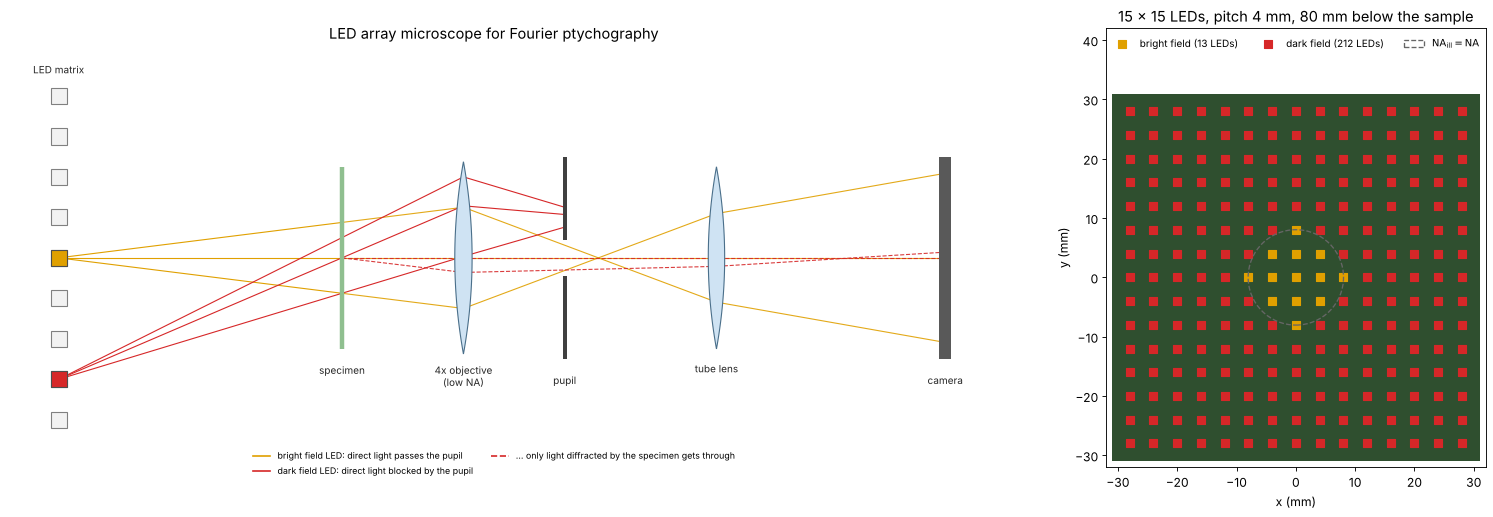

In [2]:
from pyoptics import sketch

fig = plt.figure(figsize=(20, 6.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.7, 1])
ax = fig.add_subplot(gs[0])
sketch.fpm_microscope(ax, title="LED array microscope for Fourier ptychography")
ax = fig.add_subplot(gs[1])
pos = (np.arange(n_led) - (n_led - 1)/2)*led_pitch/1e3        # mm
P_x, P_y = np.meshgrid(pos, pos)
ax.add_patch(plt.Rectangle((pos[0] - 3, pos[0] - 3), pos[-1] - pos[0] + 6, pos[-1] - pos[0] + 6,
                           facecolor="#2f4f2f", edgecolor="none"))
ax.scatter(P_x.ravel()[bright], P_y.ravel()[bright], marker="s", s=60, color="#e0a000",
           label=f"bright field ({bright.sum()} LEDs)")
ax.scatter(P_x.ravel()[~bright], P_y.ravel()[~bright], marker="s", s=60, color="#d62728",
           label=f"dark field ({(~bright).sum()} LEDs)")
r_bf = led_dist/1e3*np.tan(np.arcsin(NA))
ax.add_patch(Circle((0, 0), r_bf, fill=False, color="0.4", ls="--", lw=1.2,
                    label=r"$\mathrm{NA_{ill}} = \mathrm{NA}$"))
ax.set_aspect("equal"); ax.set_xlabel("x (mm)"); ax.set_ylabel("y (mm)")
ax.set_xlim(pos[0] - 4, pos[-1] + 4); ax.set_ylim(pos[0] - 4, pos[-1] + 4 + 10)
ax.legend(loc="upper center", ncol=3, fontsize=9, frameon=False)
ax.set_title(f"{n_led} × {n_led} LEDs, pitch {led_pitch/1e3:g} mm, {led_dist/1e3:g} mm below the sample")
plt.tight_layout()

## 1. Setup and k-space coverage

The sample is a thin object with independent amplitude and phase: a
resolution target (groups of three bars, periods from 6 µm down to
0.85 µm, as amplitude) and transparent cells (phase up to 1.5 rad). The
objective alone resolves periods down to $\lambda/\mathrm{NA} = 5.3$ µm in
coherent light. Each LED moves the pupil (radius $\mathrm{NA}$) to the
centre $-\mathrm{NA}_\mathrm{ill}$ in the object spectrum. Neighbouring
pupils overlap by about 70 % near the axis (`circle_overlap()`), the
redundancy the phase retrieval needs; together they cover a synthetic
aperture of $\mathrm{NA} + \mathrm{NA}_\mathrm{ill,max} \approx 0.54$, i.e.
periods down to 1 µm.

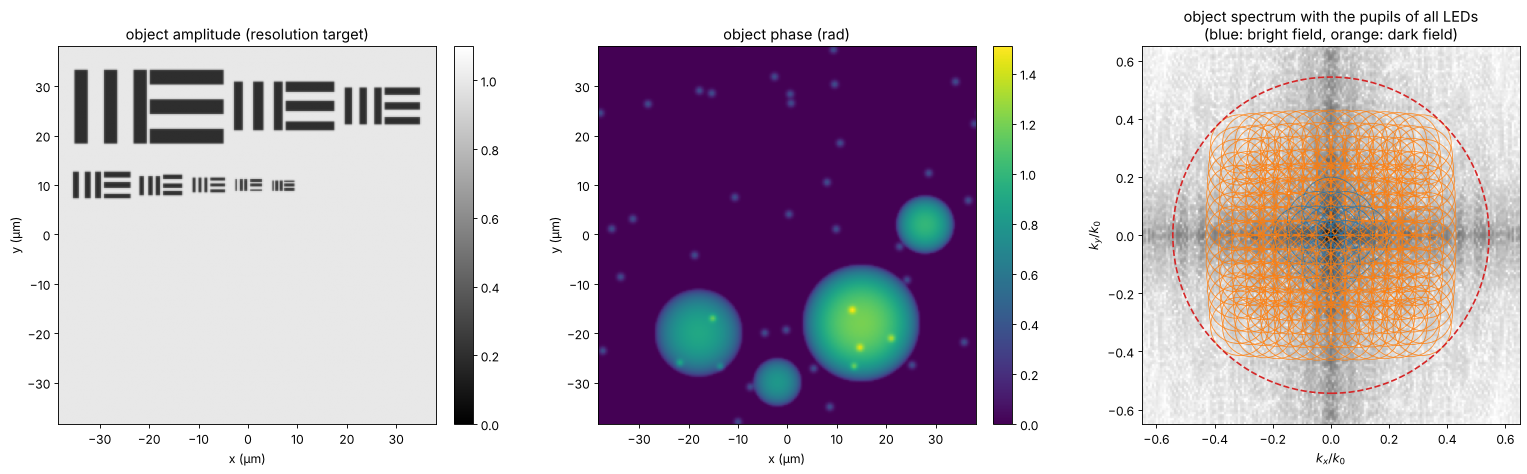

In [3]:
def bars(x0, y0, period, horizontal=False, length=None):
    # three bars of width period/2
    length = 2.5*period if length is None else length
    u, v = (Y - y0, X - x0) if horizontal else (X - x0, Y - y0)
    out = np.zeros((N, N), bool)
    for j in (-1, 0, 1):
        out |= (np.abs(u - j*period) < period/4) & (np.abs(v) < length/2)
    return out


amp = np.ones((N, N))
# two rows of groups; each group has three vertical and three horizontal bars
rows_ = [(26.0, [6.0, 4.0, 3.0]), (10.0, [2.2, 1.6, 1.25, 1.0, 0.85])]
for y_row, ps in rows_:
    x_cur = -L/2 + 3.0
    for p_ in ps:
        w = 2.5*p_
        amp[bars(x_cur + w/2, y_row, p_)] = 0.2
        amp[bars(x_cur + 1.5*w + 0.5, y_row, p_, horizontal=True, length=w)] = 0.2
        x_cur += 2*w + 2.5
amp = gaussian_filter(amp, 0.5, mode="wrap")
rng = np.random.default_rng(7)
phi = np.zeros((N, N))
for x0, y0, R, h in [(15, -18, 12, 1.2), (-18, -20, 9, 0.9), (28, 2, 6, 1.0), (-2, -30, 5, 0.8)]:
    phi += h*np.clip(1 - ((X - x0)**2 + (Y - y0)**2)/R**2, 0, None)**0.5
for _ in range(40):
    x0, y0 = rng.uniform(-L/2, L/2, 2)
    phi += 0.4*np.exp(-((X - x0)**2 + (Y - y0)**2)/(2*0.5**2))
phi = gaussian_filter(phi, 0.6, mode="wrap")
obj = amp*np.exp(1j*phi)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
show(axes[0], amp, "object amplitude (resolution target)", vmin=0, vmax=1.1)
show(axes[1], phi, "object phase (rad)", cmap="viridis")
ax = axes[2]
S = np.log10(np.abs(FT(obj))/N**2 + 1e-6)
ax.imshow(S, extent=na_extent, cmap="Greys", vmin=-5, vmax=-1)
for kx, ky, na_i in zip(k_x, k_y, NA_ill):
    ax.add_patch(Circle((-kx/k0, -ky/k0), NA, fill=False, lw=0.8,
                        color="tab:blue" if na_i <= NA else "tab:orange", alpha=0.8))
ax.add_patch(Circle((0, 0), NA + NA_ill.max(), fill=False, lw=1.5, ls="--", color="tab:red"))
ax.set_xlim(-0.65, 0.65); ax.set_ylim(-0.65, 0.65)
ax.set_xlabel(r"$k_x/k_0$"); ax.set_ylabel(r"$k_y/k_0$")
ax.set_title("object spectrum with the pupils of all LEDs\n(blue: bright field, orange: dark field)")
for a in axes[:2]:
    a.set_xlabel("x (µm)"); a.set_ylabel("y (µm)")
plt.tight_layout()

## 2. The raw images

`fpm_images()` crops the shifted spectrum with the pupil and transforms
it to the camera grid (64 × 64 pixels of 1.2 µm). The centre LED gives an
ordinary coherent bright field image, nearly blind to the phase and to
the fine bars. Oblique bright field LEDs show the phase as relief
(asymmetric illumination, notebook [52](52_abbe_image_formation.ipynb));
dark field LEDs show only edges and fine structures, at a small fraction
of the light. The camera adds shot noise: $10^4$ photons per pixel for a
clear bright field image (the dark field images get the same exposure,
hence far fewer photons).

mean signal: centre 0.893, dark field at 0.2: 0.0037, outermost: 0.00001 (relative to a clear bright field)


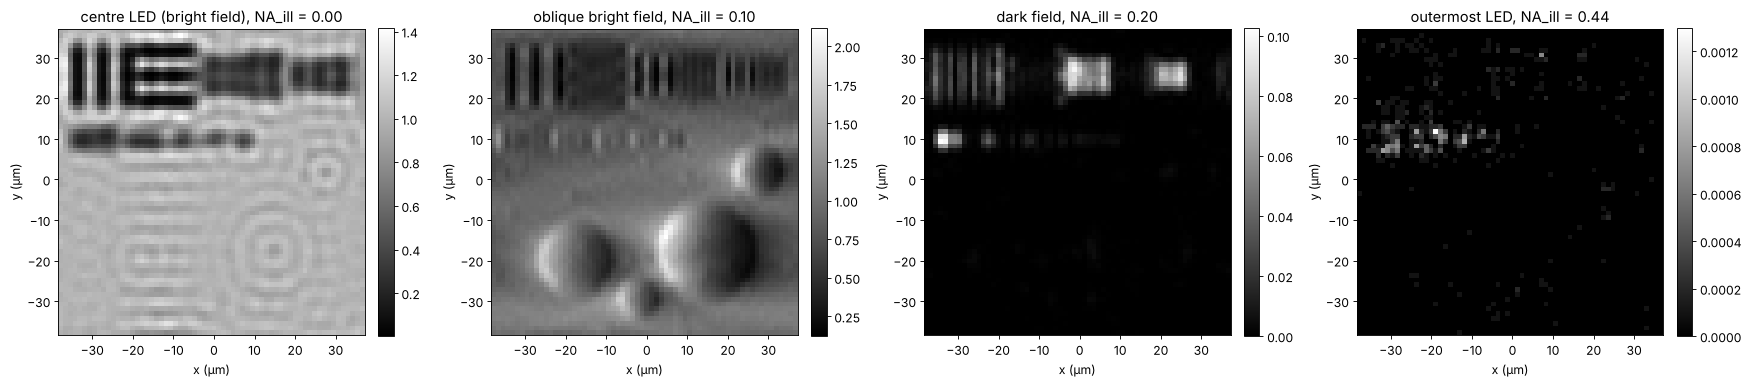

In [4]:
images_clean, x_lr, y_lr = mic.fpm_images(obj, x, y, wl, NA, k_x, k_y, m)
photons = 1e4
images = CameraNoiser("poisson", rng=1)(images_clean*photons)/photons
ext_lr = (x_lr[0], x_lr[-1], y_lr[0], y_lr[-1])
centre = np.argmin(NA_ill)
oblique = np.argmin(np.abs(NA_ill - 0.08) + np.abs(k_y))
dark1 = np.argmin(np.abs(NA_ill - 0.2) + np.abs(k_y))
dark2 = np.argmax(NA_ill)
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, j, label in zip(axes, [centre, oblique, dark1, dark2],
                        ["centre LED (bright field)", "oblique bright field", "dark field", "outermost LED"]):
    show(ax, images[j], f"{label}, NA_ill = {NA_ill[j]:.2f}", ext=ext_lr)
    ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
plt.tight_layout()
print(f"mean signal: centre {images[centre].mean():.3f}, dark field at 0.2: {images[dark1].mean():.4f}, "
      f"outermost: {images[dark2].mean():.5f} (relative to a clear bright field)")

The raw data at a glance: the images of the central 9 × 9 LEDs, each
placed where its LED sits in the matrix and each scaled to its own range
(the dark field images are much darker). The bright field disk in the
middle, the relief of the oblique LEDs at its rim and the edge images of
dark field are what the reconstruction combines.

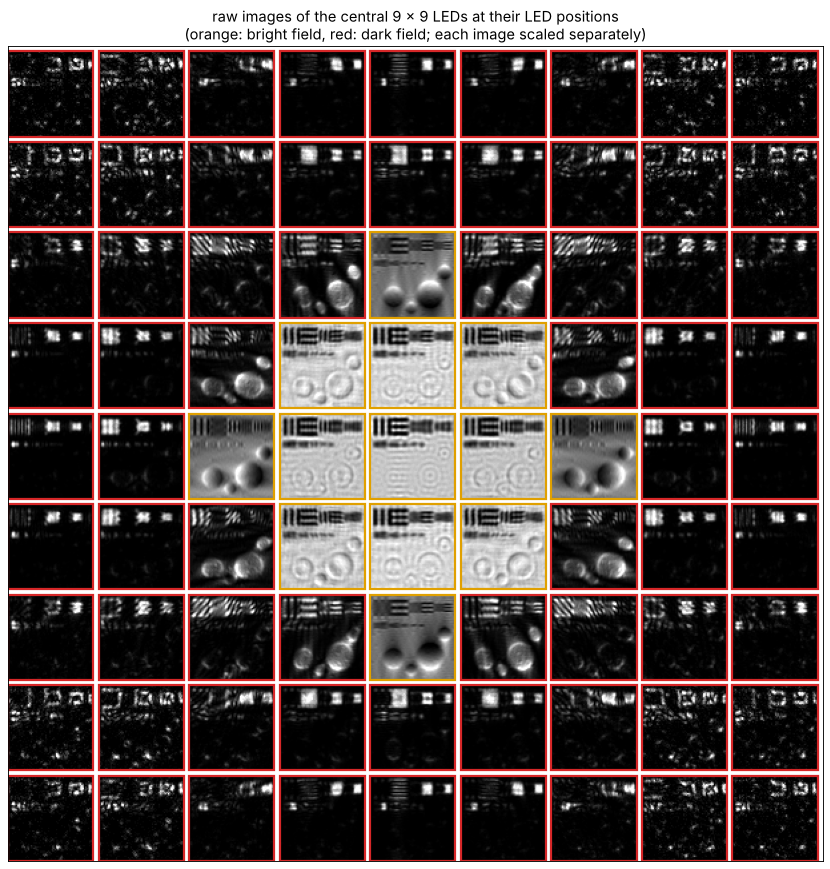

In [5]:
n_show = 9
o = (n_led - n_show)//2
gap = 4
mosaic = np.ones((n_show*(m + gap), n_show*(m + gap)))
for iy in range(n_show):
    for ix in range(n_show):
        j = (o + iy)*n_led + (o + ix)
        im = images[j]
        lo, hi = np.percentile(im, [0.5, 99.5])
        tile = np.clip((im - lo)/(hi - lo + 1e-12), 0, 1)
        mosaic[iy*(m + gap):iy*(m + gap) + m, ix*(m + gap):ix*(m + gap) + m] = tile
fig, ax = plt.subplots(figsize=(11, 11))
ax.imshow(mosaic, cmap="gray", vmin=0, vmax=1)
for iy in range(n_show):
    for ix in range(n_show):
        j = (o + iy)*n_led + (o + ix)
        ax.add_patch(plt.Rectangle((ix*(m + gap) - 0.5, iy*(m + gap) - 0.5), m, m, fill=False,
                                   lw=2, color="#e0a000" if bright[j] else "#d62728"))
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("raw images of the central 9 × 9 LEDs at their LED positions\n"
             "(orange: bright field, red: dark field; each image scaled separately)")
plt.tight_layout()

## 3. Reconstruction

`fpm_reconstruct()` starts from the up-sampled square root of the centre
image and goes through the LEDs in order of increasing illumination angle.
For each LED it cuts the current estimate of the spectrum with the shifted
pupil, propagates it to the camera, replaces the amplitude by the
measured one, and feeds the change back into the spectrum (and the pupil,
section 4). With noisy data the alternating projections converge to an
error floor set by the noise; the step size `alpha` below 1 damps the
noise in later passes. Here the pupil is known.

reconstruction: 3.6 s for 30 passes over 225 LEDs
relative error inside the synthetic aperture: 0.037


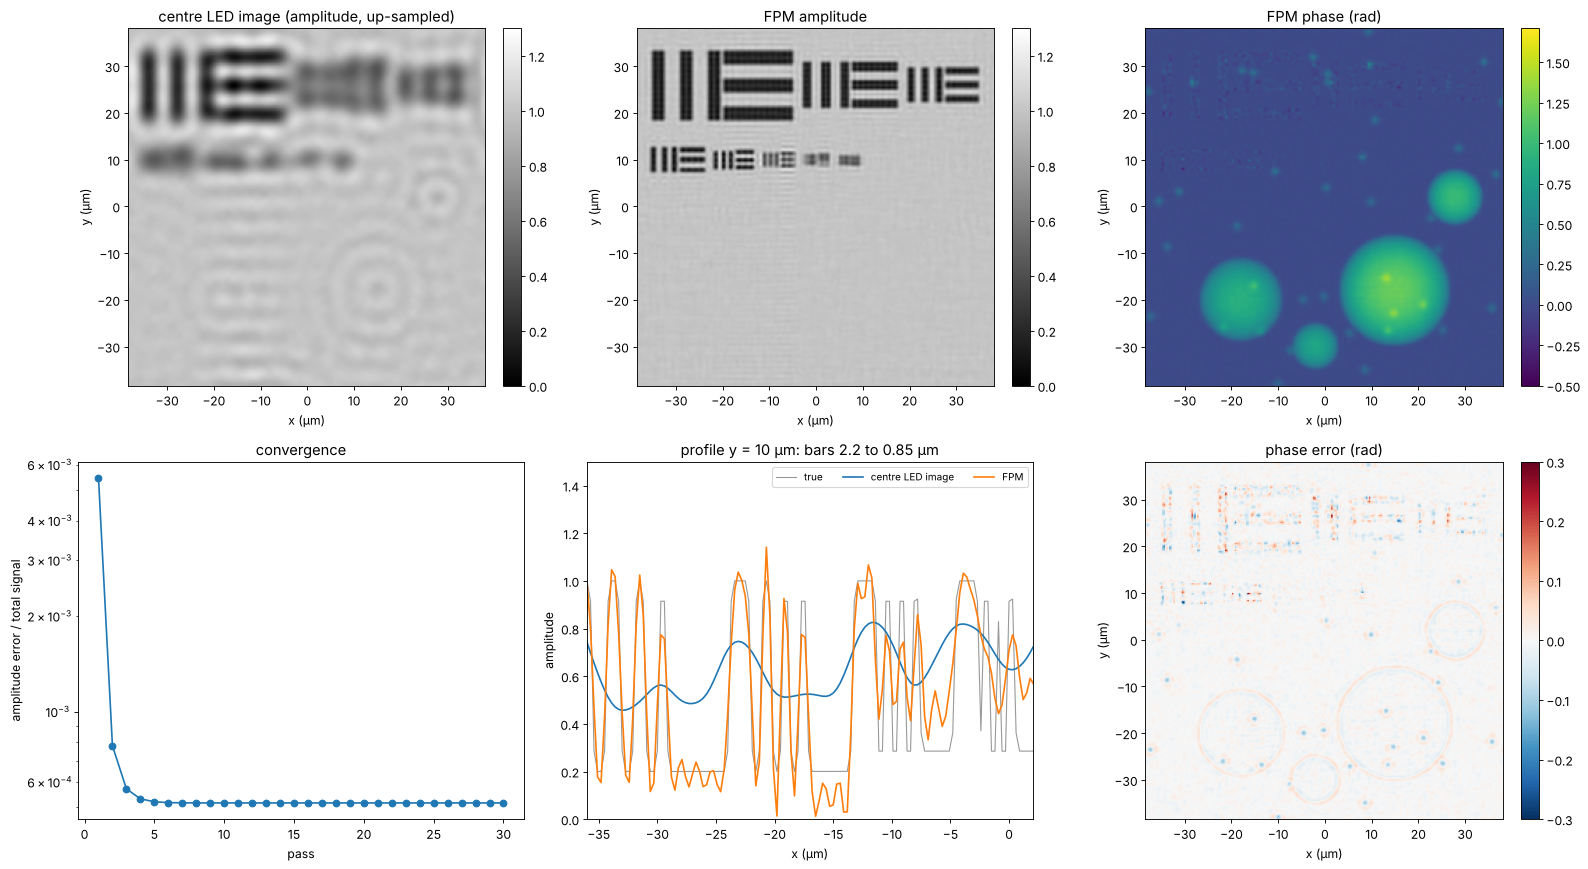

In [6]:
t0 = time.time()
rec, P_rec, err = mic.fpm_reconstruct(images, x, y, wl, NA, k_x, k_y, n_iter=30, update_pupil=False)
print(f"reconstruction: {time.time() - t0:.1f} s for 30 passes over {len(k_x)} LEDs")
synth = np.hypot(K_x, K_y) <= k0*(NA + NA_ill.max())


def aligned(field, ref):
    # remove the global complex factor (the phase is unknown in any phase retrieval)
    return field*np.vdot(field, ref)/np.vdot(field, field)


def band(field, mask=synth):
    return inv_FT(FT(field)*mask)


ref = band(obj)
rec_a = aligned(band(rec), ref)
lowres = np.sqrt(np.clip(images[centre], 0, None))
lowres_up = np.abs(inv_FT(np.pad(FT(lowres), (N - m)//2)))*(N/m)**2
print(f"relative error inside the synthetic aperture: {np.linalg.norm(rec_a - ref)/np.linalg.norm(ref):.3f}")

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
show(axes[0, 0], lowres_up, "centre LED image (amplitude, up-sampled)", vmin=0, vmax=1.3)
show(axes[0, 1], np.abs(rec_a), "FPM amplitude", vmin=0, vmax=1.3)
show(axes[0, 2], np.angle(rec_a), "FPM phase (rad)", cmap="viridis", vmin=-0.5, vmax=phi.max() + 0.2)
ax = axes[1, 0]
ax.semilogy(np.arange(1, 31), err, "o-")
ax.set_xlabel("pass"); ax.set_ylabel("amplitude error / total signal")
ax.set_title("convergence")
ax = axes[1, 1]
row = np.argmin(np.abs(y - 10))
ax.plot(x, amp[row], color="0.6", lw=1, label="true")
ax.plot(x, lowres_up[row], lw=1.5, label="centre LED image")
ax.plot(x, np.abs(rec_a[row]), lw=1.5, label="FPM")
ax.set_xlim(-36, 2); ax.set_ylim(0, 1.5); ax.set_xlabel("x (µm)"); ax.set_ylabel("amplitude")
ax.set_title("profile y = 10 µm: bars 2.2 to 0.85 µm"); ax.legend(fontsize=9, loc="upper right", ncol=3)
ax = axes[1, 2]
show(ax, np.angle(rec_a) - np.angle(ref), "phase error (rad)", cmap="RdBu_r", vmin=-0.3, vmax=0.3)
for a in [axes[0, 0], axes[0, 1], axes[0, 2], axes[1, 2]]:
    a.set_xlabel("x (µm)"); a.set_ylabel("y (µm)")
plt.tight_layout()

FPM resolves the bars down to about 1 µm, the limit
$\lambda/(\mathrm{NA} + \mathrm{NA}_\mathrm{ill})$ along $x$; the 0.85 µm group
is beyond the synthetic aperture along $x$ and $y$ (only the corner LEDs
reach that far, along the diagonals) and is lost. The phase of the cells is recovered
quantitatively. The phase error is largest where the amplitude is low
(in the bars, where the phase is ill defined) and at the finest
structures, and it contains a weak copy of the amplitude: the familiar
amplitude-phase crosstalk of FPM with noisy dark field images.

## 4. An aberrated objective: embedded pupil recovery

Cheap low NA objectives, and especially the edges of their large fields,
are aberrated. Here the pupil carries 0.3 waves of defocus (Fringe $Z_4$)
and 0.2 waves of astigmatism ($Z_5$). Reconstructing with an ideal pupil
leaves blurred and rippled images; with `update_pupil=True` (embedded
pupil recovery, Ou, Zheng and Yang 2014) the pupil is updated in each step
together with the spectrum, and the aberration comes out as a by-product.
The default update rule of `fpm_reconstruct()` is the regularized
quasi-Newton step of Tian et al. (2014), which converges faster than the
original EPRY step (`method="epry"`). Both need many more passes than
with a known pupil: here the quasi-Newton recovery wanders for some 45
passes before it locks onto the pupil and the error drops, while the EPRY
step stagnates with half the aberration left. Much larger aberrations (a wave and more) let the joint
recovery stagnate in a wrong pupil; then a calibration of the pupil on a
known sample, or a coarse search of the defocus first, helps. Pupil and
object share ambiguities: a common complex factor (`fpm_reconstruct()`
scales the pupil to a mean magnitude of 1) and a pupil tilt, which is the
same as a shift of the object; piston and tilt are removed before
comparing.

pupil error 0.010 waves rms (aberration 0.193 waves rms)
EPRY step: pupil error 0.164 waves rms
ideal pupil assumed   : relative error 0.313
with pupil recovery   : relative error 0.063
EPRY step             : relative error 0.267


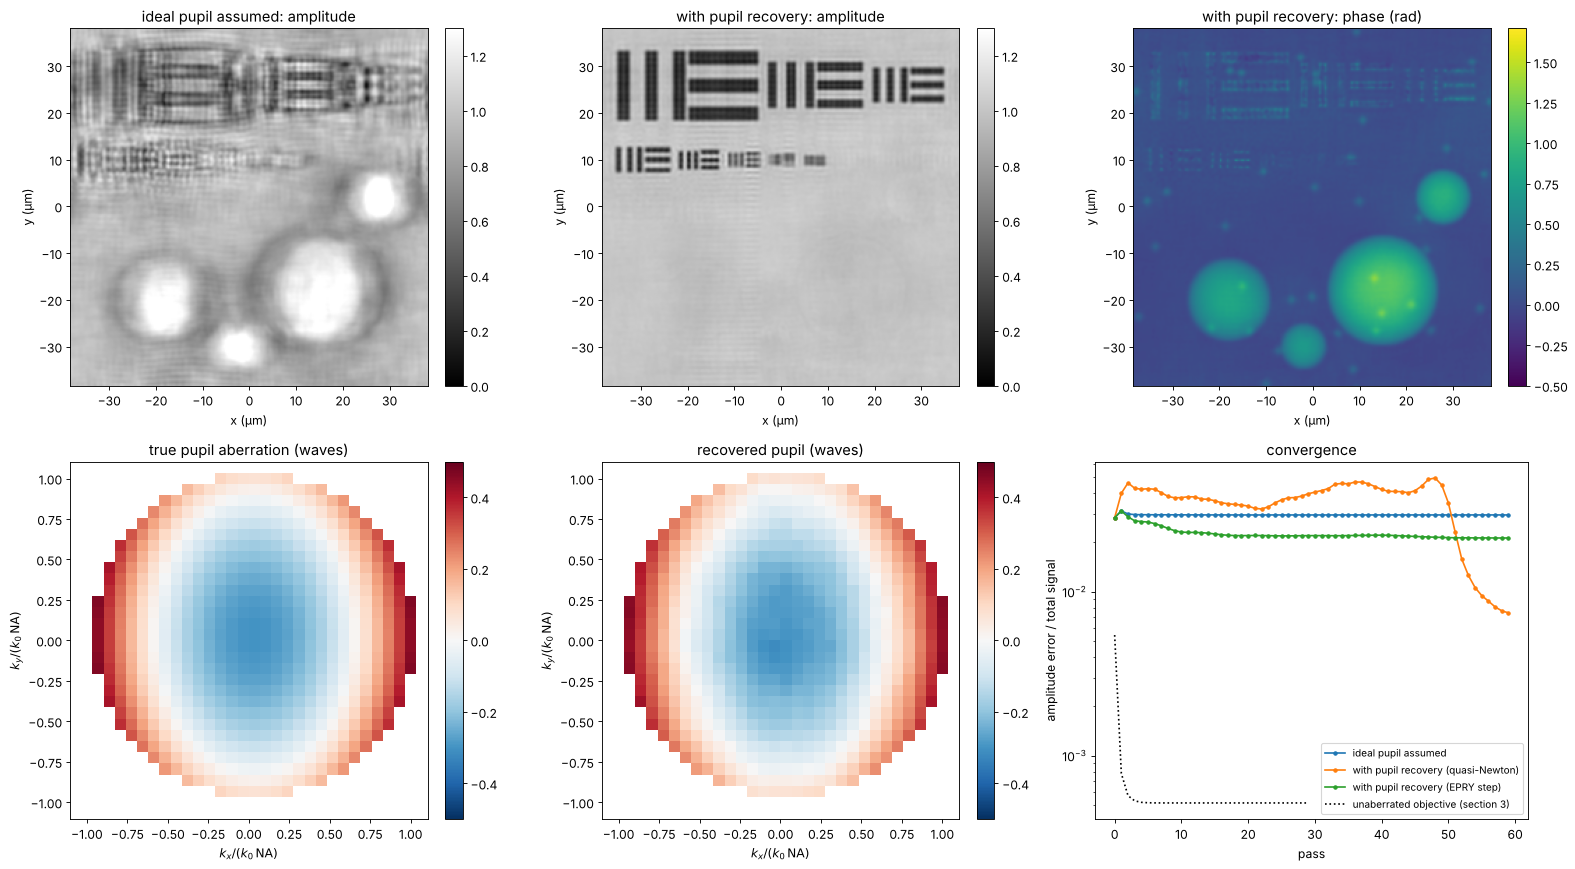

In [7]:
P0, x_p, y_p = mic.fpm_pupil(x, y, m, wl, NA)
Kp_x, Kp_y = freq_grid(x_p, y_p)
rho_x, rho_y = Kp_x/(k0*NA), Kp_y/(k0*NA)
inside = np.abs(P0) > 0
W = 0.3*fringe_zernike(4, rho_x, rho_y) + 0.2*fringe_zernike(5, rho_x, rho_y)   # waves
P_true = P0*np.exp(2j*np.pi*W)
images_ab = CameraNoiser("poisson", rng=2)(mic.fpm_images(obj, x, y, wl, NA, k_x, k_y, m,
                                                           P=P_true)[0]*photons)/photons
n_ab = 60
rec_fixed, _, err_fixed = mic.fpm_reconstruct(images_ab, x, y, wl, NA, k_x, k_y, n_iter=n_ab,
                                              update_pupil=False)
rec_epry, P_epry, err_epry = mic.fpm_reconstruct(images_ab, x, y, wl, NA, k_x, k_y, n_iter=n_ab,
                                                 update_pupil=True)
rec_ou, P_ou, err_ou = mic.fpm_reconstruct(images_ab, x, y, wl, NA, k_x, k_y, n_iter=n_ab,
                                           update_pupil=True, method="epry")


def pupil_waves(P):
    # pupil phase in waves, piston and tilt removed by a least squares fit of the
    # difference to the true pupil (small, so no unwrapping is needed)
    d = np.angle(P*np.conj(P_true))
    A = np.stack([np.ones(inside.sum()), rho_x[inside], rho_y[inside]], axis=1)
    c, *_ = np.linalg.lstsq(A, d[inside], rcond=None)
    out = np.full(P.shape, np.nan)
    out[inside] = np.angle(P[inside]*np.exp(-1j*(A @ c)))/(2*np.pi)
    return out


W_rec = pupil_waves(P_epry)
W_ref = pupil_waves(P_true)
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, r, title in [(axes[0, 0], rec_fixed, "ideal pupil assumed: amplitude"),
                     (axes[0, 1], rec_epry, "with pupil recovery: amplitude")]:
    show(ax, np.abs(aligned(band(r), ref)), title, vmin=0, vmax=1.3)
show(axes[0, 2], np.angle(aligned(band(rec_epry), ref)), "with pupil recovery: phase (rad)",
     cmap="viridis", vmin=-0.5, vmax=phi.max() + 0.2)
crop = (slice(m//2 - 16, m//2 + 16),)*2
ext_p = (-16*(Kp_x[0, 1] - Kp_x[0, 0])/(k0*NA), 16*(Kp_x[0, 1] - Kp_x[0, 0])/(k0*NA))*2
show(axes[1, 0], W_ref[crop], "true pupil aberration (waves)", cmap="RdBu_r", ext=ext_p, vmin=-0.5, vmax=0.5)
show(axes[1, 1], W_rec[crop], "recovered pupil (waves)", cmap="RdBu_r", ext=ext_p, vmin=-0.5, vmax=0.5)
ax = axes[1, 2]
ax.semilogy(err_fixed, "o-", ms=3, label="ideal pupil assumed")
ax.semilogy(err_epry, "o-", ms=3, label="with pupil recovery (quasi-Newton)")
ax.semilogy(err_ou, "o-", ms=3, label="with pupil recovery (EPRY step)")
ax.semilogy(err, "k:", label="unaberrated objective (section 3)")
ax.set_xlabel("pass"); ax.set_ylabel("amplitude error / total signal"); ax.legend(fontsize=9)
ax.set_title("convergence")
for a in axes[0]:
    a.set_xlabel("x (µm)"); a.set_ylabel("y (µm)")
for a in axes[1, :2]:
    a.set_xlabel(r"$k_x/(k_0\,\mathrm{NA})$"); a.set_ylabel(r"$k_y/(k_0\,\mathrm{NA})$")
plt.tight_layout()
rms = np.sqrt(np.nanmean((W_rec - W_ref)**2))
print(f"pupil error {rms:.3f} waves rms (aberration {np.sqrt(np.nanmean(W_ref**2)):.3f} waves rms)")
print(f"EPRY step: pupil error {np.sqrt(np.nanmean((pupil_waves(P_ou) - W_ref)**2)):.3f} waves rms")
for name, r in [("ideal pupil assumed", rec_fixed), ("with pupil recovery", rec_epry),
                ("EPRY step", rec_ou)]:
    print(f"{name:22s}: relative error {np.linalg.norm(aligned(band(r), ref) - ref)/np.linalg.norm(ref):.3f}")

## 5. LED overlap and noise

FPM needs redundancy: each part of the spectrum must be seen by several
LEDs. The overlap between neighbouring pupils is set by the LED pitch
and distance; below about 40 % the reconstruction degrades quickly, as
found experimentally (Sun et al. 2016). The scan keeps the largest
illumination angle near 0.33 (the outermost row) and changes the LED
pitch, with and without shot noise, 20 passes each.

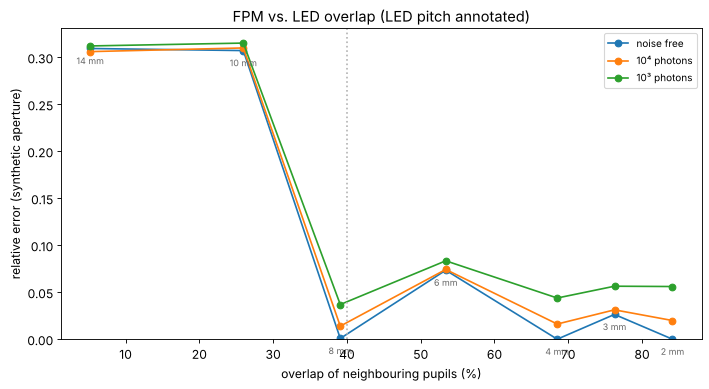

In [8]:
pitches = [2.0, 3.0, 4.0, 6.0, 8.0, 10.0, 14.0]   # mm
results = {"noise free": [], "10⁴ photons": [], "10³ photons": []}
overlaps = []
for pm in pitches:
    n_side = 2*int(round(28.0/pm)) + 1
    kx_, ky_, na_ = mic.led_array(n_side, pm*1e3, led_dist, wl)
    overlaps.append(mic.circle_overlap(k0*pm*1e3/led_dist, k0*NA))
    clean, _, _ = mic.fpm_images(obj, x, y, wl, NA, kx_, ky_, m)
    syn = np.hypot(K_x, K_y) <= k0*(NA + 0.33)
    ref_ = band(obj, syn)
    for name, ph in [("noise free", None), ("10⁴ photons", 1e4), ("10³ photons", 1e3)]:
        data = clean if ph is None else CameraNoiser("poisson", rng=3)(clean*ph)/ph
        r, _, _ = mic.fpm_reconstruct(data, x, y, wl, NA, kx_, ky_, n_iter=20, update_pupil=False)
        results[name].append(np.linalg.norm(aligned(band(r, syn), ref_) - ref_)/np.linalg.norm(ref_))
fig, ax = plt.subplots(figsize=(9, 5))
for name, r in results.items():
    ax.plot(np.array(overlaps)*100, r, "o-", label=name)
for pm, o in zip(pitches, overlaps):
    ax.annotate(f"{pm:g} mm", (o*100, results["noise free"][pitches.index(pm)]),
                textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color="0.4")
ax.axvline(40, color="0.7", ls=":")
ax.set_xlabel("overlap of neighbouring pupils (%)"); ax.set_ylabel("relative error (synthetic aperture)")
ax.set_title("FPM vs. LED overlap (LED pitch annotated)"); ax.legend(fontsize=9)
ax.set_ylim(0, None)
plt.tight_layout()

With little overlap the patches of the spectrum are retrieved
independently, each with its own unknown phase offset, and the stitching
fails. Above about 40 % the reconstruction works, with some scatter from
the convergence within 20 passes (the bump at 6 mm). More LEDs do not
remove the noise error here: it comes mostly from the photon starved dark
field images.
Dense arrays cost acquisition time (225 images here, more for wider
synthetic apertures), which is why later work multiplexes several LEDs
per image (Tian et al. 2014).

## 6. Space-bandwidth product

The figures of merit for this example, with the full camera of a
typical microscope (2048 × 2048 pixels of 4.8 µm behind the 4×
objective):

In [9]:
fov = 2048*pixel/M                     # mm scale field of the full camera, um
rows = [("4x / 0.10 objective (coherent, centre LED)", NA, wl/NA, fov),
        ("4x / 0.10 with FPM, NA_syn = 0.54", NA + NA_ill.max(), wl/(NA + NA_ill.max()), fov),
        ("20x / 0.50 objective (coherent)", 0.5, wl/0.5, 2048*6.5/20)]
print(f"{'system':45s}{'NA':>6s}{'period (um)':>13s}{'field (mm)':>12s}{'SBP (Mpixel)':>14s}")
for name, na, res, f in rows:
    sbp = (f/(res/2))**2/1e6   # Nyquist pixels across the field
    print(f"{name:45s}{na:6.2f}{res:13.2f}{f/1000:12.2f}{sbp:14.1f}")
print(f"\nrun time {time.time() - t_start:.0f} s")

system                                           NA  period (um)  field (mm)  SBP (Mpixel)
4x / 0.10 objective (coherent, centre LED)     0.10         5.30        2.46           0.9
4x / 0.10 with FPM, NA_syn = 0.54              0.54         0.97        2.46          25.4
20x / 0.50 objective (coherent)                0.50         1.06        0.67           1.6

run time 101 s


FPM keeps the 2.5 mm field of the 4× objective and resolves like a
0.5 NA objective, whose field is almost four times smaller in diameter:
about 30 times the space-bandwidth product of the 4× objective and 15
times that of the 20× objective, in exchange for 225 exposures and a
computation. The simulation leaves out what makes real FPM harder:
the LED positions must be calibrated (they are rounded to the
frequency grid here, an error of up to half a sample), the LED intensities
fall off with $\cos^4\theta$ and differ from LED to LED, each LED has a
finite size (partial coherence), the camera has a background and read
noise, the sample is not perfectly thin, and the aberrations vary over the
field, so the field is reconstructed in tiles, each with its own pupil.

## Summary

- Each LED shifts the object spectrum; its low resolution image holds the
  intensity of one disk of the spectrum. LEDs beyond the NA give dark
  field images of the high frequencies.
- `fpm_reconstruct()` stitches the disks together by alternating
  projections; it recovers amplitude and quantitative phase with the
  resolution of the synthetic aperture $\mathrm{NA} + \mathrm{NA}_\mathrm{ill}$.
- With `update_pupil=True` (EPRY) the objective's aberrations are
  recovered as well, and the image is corrected for them.
- Neighbouring pupils must overlap by more than about 40 %
  (`circle_overlap()`); the redundancy also suppresses noise.
- The space-bandwidth product grows by the square of the NA gain, here
  about 30 times over the objective used.

## References

- G. Zheng, R. Horstmeyer and C. Yang, "Wide-field, high-resolution Fourier ptychographic microscopy", Nat. Photonics 7, 739-745 (2013).
- X. Ou, G. Zheng and C. Yang, "Embedded pupil function recovery for Fourier ptychographic microscopy", Opt. Express 22, 4960-4972 (2014).
- L. Tian, X. Li, K. Ramchandran and L. Waller, "Multiplexed coded illumination for Fourier ptychography with an LED array microscope", Biomed. Opt. Express 5, 2376-2389 (2014).
- L.-H. Yeh, J. Dong, J. Zhong, L. Tian, M. Chen, G. Tang, M. Soltanolkotabi and L. Waller, "Experimental robustness of Fourier ptychography phase retrieval algorithms", Opt. Express 23, 33214-33240 (2015).
- J. Sun, Q. Chen, Y. Zhang and C. Zuo, "Sampling criteria for Fourier ptychographic microscopy in object space and frequency space", Opt. Express 24, 15765-15781 (2016).
- J. M. Rodenburg and H. M. L. Faulkner, "A phase retrieval algorithm for shifting illumination", Appl. Phys. Lett. 85, 4795-4797 (2004).
- J. R. Fienup, "Phase retrieval algorithms: a comparison", Appl. Opt. 21, 2758-2769 (1982).
- P. C. Konda, L. Loetgering, K. C. Zhou, S. Xu, A. R. Harvey and R. Horstmeyer, "Fourier ptychography: current applications and future promises", Opt. Express 28, 9603-9630 (2020).